# Pauli-X results
Two figures: entropy versus size, and entropy density versus probability, each with a detailed high-probability panel. Shading is one SEM using the actual realisation count. No simulations run here.

Place `pauli_plotting.py` in `src/monitored_cluster_states/` and this notebook in `notebooks/`. Select a file explicitly if the directory contains several datasets.


In [2]:
from monitored_cluster_states.paths import DATA_DIR, FIGURES_DIR
import monitored_cluster_states.pauli_plotting as plotting
import importlib
import numpy as np
import matplotlib.pyplot as plt

plotting = importlib.reload(plotting)


In [3]:
BASIS = "x"
FILE_NAME = None  # Set to the exact .pkl filename if several files exist.
MAX_P_CURVES = 10  # Set to None to show all stored probabilities on the left.
SHOW_SEM = True
SAVE_PDF = True
output_dir = FIGURES_DIR / f"pauli_{BASIS}" if SAVE_PDF else None

results = plotting.load_pauli_results(
    DATA_DIR / f"pauli_{BASIS}", FILE_NAME, basis=BASIS,
)
print("Loaded:", results["data_file"])
print("Protocol:", results["metadata"].get("measurement_protocol", "not recorded"))
print("Periodic:", results["metadata"].get("periodic", "not recorded"))
counts = results["counts"][results["counts"] > 0]
print("Realisations per point:", counts.min(), "to", counts.max())

# Select actual stored probabilities and all available sizes.
p_values = results["probabilities"]
n_curves = len(p_values) if MAX_P_CURVES is None else min(MAX_P_CURVES, len(p_values))
p_indices = np.unique(np.linspace(0, len(p_values) - 1, n_curves, dtype=int))
P_TARGETS = p_values[p_indices]
L_TARGETS = results["sizes"]


Loaded: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\data_files\pauli_x\pauli_x_results_PBC_binary_rank_all_Lmax_80.pkl
Protocol: X_current_graph_pivot_delete_with_local_corrections
Periodic: True
Realisations per point: 50 to 50


## Entropy density versus probability
Left: full range. Right: zoom from 0.85 to 1, matching the supplied notebook. Mean and SEM are both divided by L.

Selected sizes: [40 50 60 70 80]
Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\results\figures\pauli_x\pauli_x_results_PBC_binary_rank_all_Lmax_80_S_over_L_vs_p_two_panels.pdf


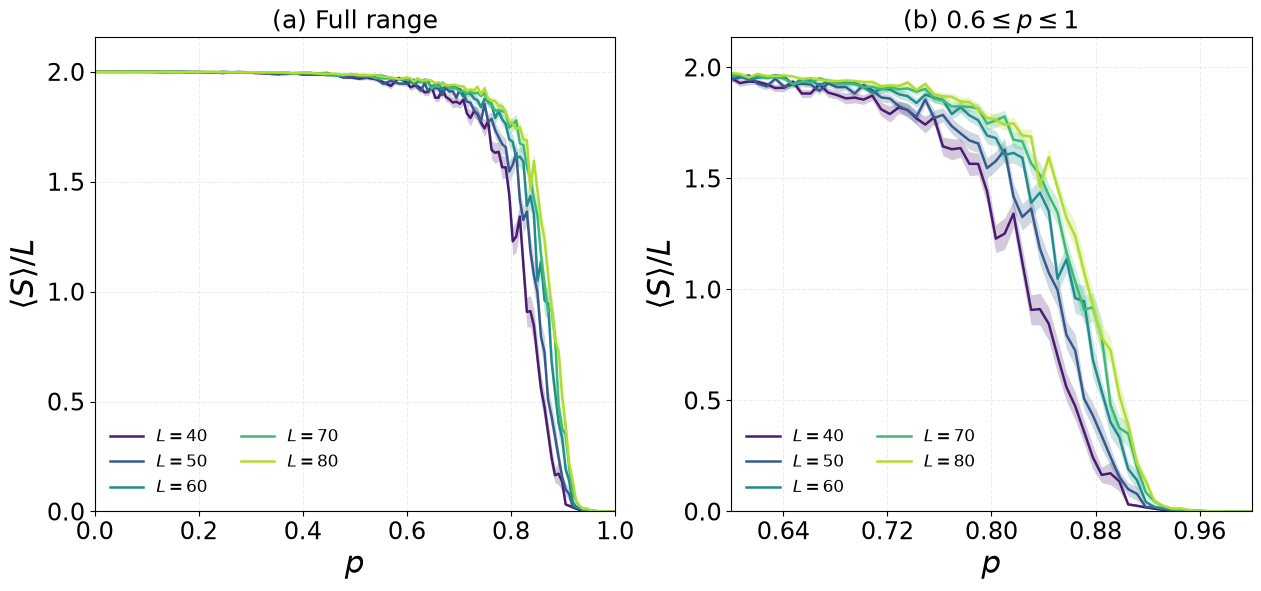

In [4]:
density_plot = plotting.plot_pauli_density_vs_p(
    results, output_dir, L_targets=L_TARGETS,
    zoom=(0.6, 1.0), show_sem=SHOW_SEM,
)
plt.show()


## Entropy versus size
Left: probabilities nearest the selected targets. Right: all stored probabilities in the zoom interval.

Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations-main\results\figures\pauli_x\pauli_x_results_PBC_binary_rank_all_Lmax_80_S_vs_L_two_panels.pdf
Actual selected probabilities: [0.         0.15384615 0.32307692 0.49230769 0.62711864 0.70169492
 0.77627119 0.85084746 0.92542373 1.        ]


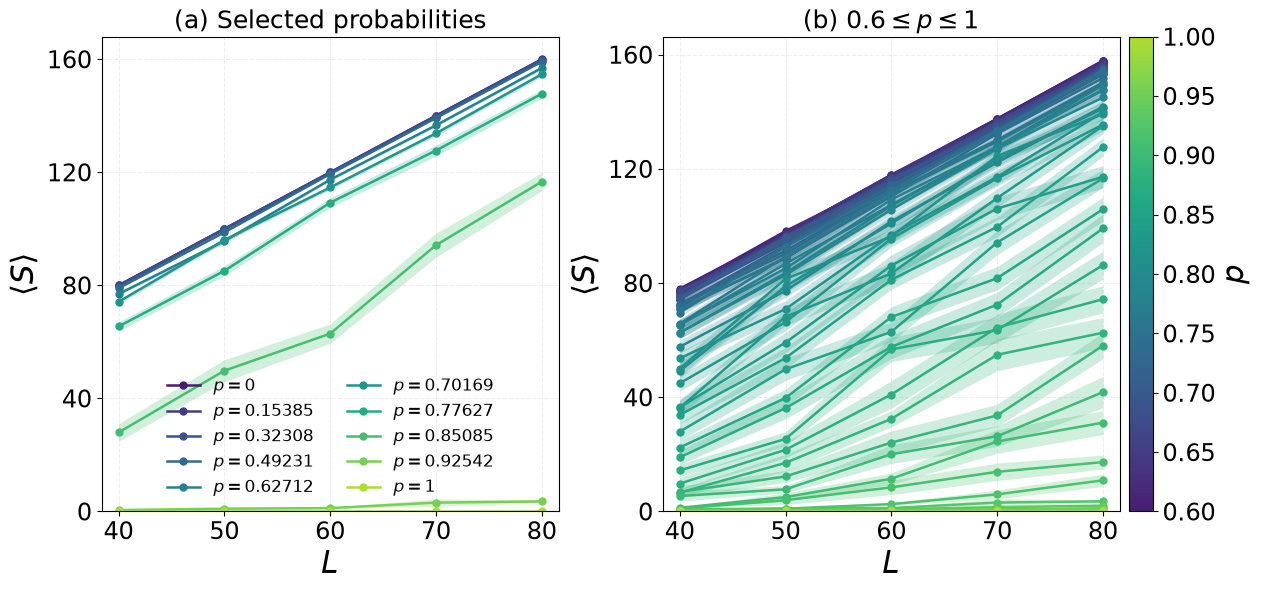

In [13]:
size_plot = plotting.plot_pauli_entropy_vs_L(
    results, output_dir, p_targets=P_TARGETS,
    zoom=(0.6, 1.0), show_sem=SHOW_SEM,
)
print("Actual selected probabilities:", size_plot["selected_probabilities"])
plt.show()
